In [4]:

import zipfile
import os
import glob
import pandas as pd
import numpy as np

print("Libraries imported successfully!")


Libraries imported successfully!


In [5]:

zip_path = '/content/archive.zip'

with zipfile.ZipFile(zip_path, 'r') as z:
    print("Files inside ZIP:")
    for name in z.namelist():
        print(name)


Files inside ZIP:
spam.csv


In [6]:

extract_folder = '/content/sms_spam_data'

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract_folder)

print("ZIP extracted successfully!")
print("Extracted files:", os.listdir(extract_folder))


ZIP extracted successfully!
Extracted files: ['spam.csv']


In [7]:

csv_files = glob.glob(
    '/content/sms_spam_data/**/*.csv',
    recursive=True
)

print("CSV files found:", csv_files)


CSV files found: ['/content/sms_spam_data/spam.csv']


In [8]:

df = pd.read_csv(csv_files[0], encoding='latin-1')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (5572, 5)


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [9]:

if {'label', 'message'}.issubset(df.columns):
    data = df[['label', 'message']].copy()
elif {'v1', 'v2'}.issubset(df.columns):
    data = df[['v1', 'v2']].copy()
    data.columns = ['label', 'message']
else:
    raise ValueError(
        f"Unexpected columns: {df.columns.tolist()}"
    )

data = data.dropna(subset=['label', 'message'])
data['label'] = data['label'].astype(str).str.strip().str.lower()
data['message'] = data['message'].astype(str).str.strip()

data = data[data['label'].isin(['ham', 'spam'])]
data = data.drop_duplicates(subset=['label', 'message'])
data = data[data['message'] != '']

print("Clean dataset shape:", data.shape)
print(data['label'].value_counts())
display(data.head())


Clean dataset shape: (5158, 2)
label
ham     4516
spam     642
Name: count, dtype: int64


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [10]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    data['message'],
    data['label'],
    test_size=0.2,
    random_state=42,
    stratify=data['label']
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))


Training messages: 4126
Testing messages: 1032


In [12]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

model = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('classifier', MultinomialNB())
])

model.fit(X_train, y_train)

print("Naive Bayes model trained successfully!")


Naive Bayes model trained successfully!


In [13]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=['ham', 'spam']))


Accuracy: 95.54 %

Classification Report:
              precision    recall  f1-score   support

         ham       0.95      1.00      0.98       904
        spam       1.00      0.64      0.78       128

    accuracy                           0.96      1032
   macro avg       0.98      0.82      0.88      1032
weighted avg       0.96      0.96      0.95      1032

Confusion Matrix:
[[904   0]
 [ 46  82]]


In [14]:

messages = [
    "Congratulations! You have won a free prize. Claim now!",
    "Hey, are we meeting at college tomorrow?",
    "URGENT! You have won a cash reward. Call now!"
]

predictions = model.predict(messages)

for message, prediction in zip(messages, predictions):
    result = "SPAM" if prediction == "spam" else "NOT SPAM"
    print(f"Message: {message}")
    print(f"Prediction: {result}\n")


Message: Congratulations! You have won a free prize. Claim now!
Prediction: SPAM

Message: Hey, are we meeting at college tomorrow?
Prediction: NOT SPAM

Message: URGENT! You have won a cash reward. Call now!
Prediction: SPAM



In [15]:

message = input("Enter an SMS message: ")

prediction = model.predict([message])[0]
probabilities = model.predict_proba([message])[0]
classes = model.named_steps['classifier'].classes_

spam_probability = probabilities[list(classes).index('spam')]

print("\nPrediction:", prediction.upper())
print(f"Estimated spam probability: {spam_probability * 100:.2f}%")


Enter an SMS message: Congratulations! You have won a free prize. Claim now!   Copy test message

Prediction: SPAM
Estimated spam probability: 62.73%


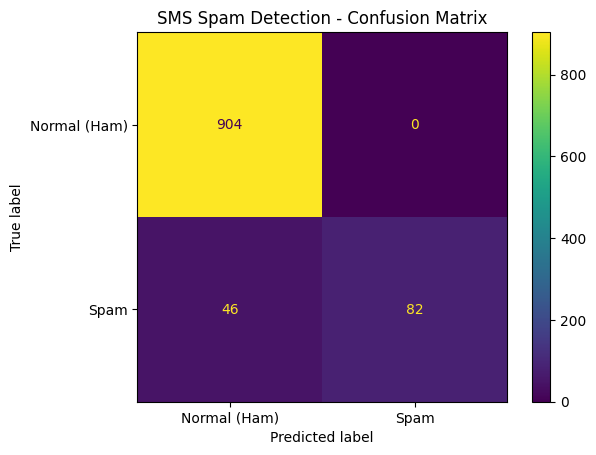

Confusion matrix:
[[904   0]
 [ 46  82]]


In [17]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = model.predict(X_test)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['ham', 'spam']
)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Normal (Ham)', 'Spam']
)

display_matrix.plot()
plt.title("SMS Spam Detection - Confusion Matrix")
plt.show()

print("Confusion matrix:")
print(cm)


In [18]:

from sklearn.metrics import accuracy_score

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred) * 100

print(f"Model Accuracy: {accuracy:.2f}%")


Model Accuracy: 95.54%
